# 7. Deep Learning: LSTM

| | |
|---|---|
| **Entra** | `datasets/procesado/4_dataset_seleccion.csv` — objetivo, partición y orígenes |
| | `datasets/procesado/2_dataset_procesado.csv` — la serie diaria con la que se arma la ventana |
| | `datasets/procesado/5_predicciones_sarimax.csv` y `6_predicciones_xgboost.csv` — para comparar |
| **Sale** | `7_predicciones_lstm.csv`, `7_metricas_lstm.csv`, `7_error_por_horizonte_lstm.csv` |
| | `models/baseline/LSTM/lstm_base.keras` |
| | filas en `resultados_modelos.csv`, una por cada una de las tres lecturas |
| **Módulo** | `_resultados.py` |

## 1. Qué hace este notebook, y en qué se aparta de los dos anteriores

Entrena la familia de Deep Learning sobre el mismo problema: desde cada origen, pronosticar los treinta días siguientes.

### 1.1 Por qué la red lee una ventana y no las 38 columnas

Los dos modelos anteriores leen una fila por origen con 38 columnas ya derivadas: rezagos de 1, 7, 14 y 30 días, medias móviles de 7 y 30, y diferencias de 1 y 30.

### 1.2 Y sin embargo no son datos distintos

La ventana no contiene *otra* información: contiene la misma, y la contiene toda.

In [1]:
# ============================================================
# 2. Configuración
# ============================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # silencia los avisos de compilación de TensorFlow

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

PROC = os.path.join("datasets", "procesado")
MODELOS = os.path.join("models", "baseline", "LSTM")
os.makedirs(MODELOS, exist_ok=True)

HORIZONTE = 30                                    # días; el horizonte de mediano plazo del trabajo
VENTANA = 31                                      # días de historia que lee la red: [t-30, t]
PASO_WFV = 60                                     # cada cuántos orígenes se reajusta el modelo
SEMILLAS = [42, 7, 123, 2024, 99]                 # las mismas cinco de los notebooks 4 y 6

FIN_ENTRENAMIENTO = pd.Timestamp("2022-12-31")
INICIO_PRUEBA = pd.Timestamp("2023-02-01")        # entre medias, todo enero de 2023: el embargo

# Las cuatro variables continuas de la selección. El día de la semana entra aparte, como estática,
# porque no es una serie que la red deba recorrer.
VARS = ["precio_bolsa", "aportes_energia", "vertimientos", "gen_hidraulica"]

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.config.threading.set_intra_op_parallelism_threads(os.cpu_count())

# Determinismo: `set_random_seed` fija las semillas de Python, NumPy y TensorFlow, pero algunas
# operaciones de GPU y de CPU multihilo siguen siendo no deterministas por el orden en que suman.
# Sin esto, dos corridas con la misma semilla pueden dar cifras distintas en los últimos decimales,
# y un trabajo que se defiende tiene que poder reproducir sus números exactamente.
tf.config.experimental.enable_op_determinism()

print(f"TensorFlow {tf.__version__}  |  GPU: {tf.config.list_physical_devices('GPU') or 'ninguna, se usa CPU'}")
print(f"Ventana de {VENTANA} días x {len(VARS)} variables  ->  {HORIZONTE} salidas por origen")

# ============================================================
# La escala de pagina de las figuras
# ============================================================
# El documento inserta toda figura al ancho de su columna, 6.332.220 EMU = 6,92 pulgadas. Una
# figura dibujada a 13 pulgadas cabe ahi, pero ENCAJADA: todo su texto se reduce en la misma
# proporcion, y un cuerpo de 10 puntos acaba en 5,4 sobre el papel, que no se lee impreso.
#
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la propia
# figura, que vale 100 mientras no se diga otra cosa: el backend en linea llama a print_figure
# con dpi=fig.dpi de forma explicita. Por eso `a_escala` la fija sobre la figura.
PPP_PAGINA, ANCHO_PX = 186, 1289
ANCHO_PAGINA = ANCHO_PX / PPP_PAGINA                     # 6,93 pulgadas

# EL RECORTE DEL BACKEND EN LINEA DESHACE ESTA ESCALA, y hay que desactivarlo. Por omision la
# figura se guarda con bbox_inches="tight", es decir ajustada a su contenido y no al tamano que se
# le dio: con letra pequena eso recorta unos pixeles de margen, pero con letra del cuerpo del
# documento los rotulos no caben en el lienzo y la imagen se ENSANCHA. Una imagen mas ancha
# insertada en el mismo ancho de columna tiene mas pixeles por pulgada, luego su letra se ve mas
# pequena: la rejilla de distribuciones pasaba de 1289 a 1633 pixeles y sus 10 puntos se veian a
# 7,9. Sin recorte, cada figura sale a ANCHO_PAGINA x PPP_PAGINA y un punto del dibujo es un punto
# del papel. El reparto del espacio lo hace `tight_layout`, que es lo que ya se llama.
try:
    get_ipython().run_line_magic(
        "config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass                                   # ejecutado como script: no hay backend en linea


def alto_pagina(ancho_viejo, alto_viejo):
    """El alto que conserva la proporcion de la figura al llevarla al ancho de la pagina."""
    return ANCHO_PAGINA * alto_viejo / ancho_viejo


def a_escala(fig, cuerpo=10.0):
    """Lleva la figura a la escala de la pagina: resolucion y tamaños de letra.

    EL CUERPO ES EL DEL DOCUMENTO, 10 puntos, y no uno menor. Una figura se inserta al ancho de
    la columna, de modo que a esta escala cada punto tipografico es un punto sobre el papel: si
    la figura se dibuja con letra de 7, el lector la ve a 7 junto a un texto de 10 y no la lee
    impresa. Los numeros de los ejes y la leyenda van al mismo cuerpo que el texto, sin descuento,
    y solo el titulo sube un punto por encima.

    LO QUE NO QUEPA CON ESA LETRA SOBRA DE LA FIGURA. El tamaño no se baja para que entre un
    rotulo largo; se acorta el rotulo, o se le da mas alto a la figura.

    Se llama ANTES de tight_layout, para que el reparto del espacio cuente ya con el tamaño
    definitivo del texto.
    """
    fig.set_dpi(PPP_PAGINA)
    for ax in fig.get_axes():
        ax.title.set_fontsize(cuerpo + 1.0)
        ax.xaxis.label.set_fontsize(cuerpo)
        ax.yaxis.label.set_fontsize(cuerpo)
        ax.tick_params(axis="both", labelsize=cuerpo)
        for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
            etiqueta.set_fontsize(cuerpo)
        leyenda = ax.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(cuerpo)
    return fig


TensorFlow 2.15.0  |  GPU: ninguna, se usa CPU
Ventana de 31 días x 4 variables  ->  30 salidas por origen


## 3. Los datos: la ventana, y la comprobación de que contiene lo mismo

Se leen dos archivos.

In [2]:
# ============================================================
# 3.1 Lectura de los dos archivos
# ============================================================
s = pd.read_csv(os.path.join(PROC, "4_dataset_seleccion.csv"),
                parse_dates=["fecha", "fecha_objetivo"])
diario = pd.read_csv(os.path.join(PROC, "2_dataset_procesado.csv"), parse_dates=["fecha"])
diario = diario[["fecha"] + VARS].set_index("fecha").asfreq("D")

assert ((s["fecha_objetivo"] - s["fecha"]).dt.days == HORIZONTE).all(), \
    "La fecha objetivo debe ser el origen + 30 días"
assert diario.notna().all().all(), "la serie diaria tiene huecos"
assert diario.index.min() <= s["fecha"].min() - pd.Timedelta(days=VENTANA - 1), \
    "la serie diaria no cubre la ventana del primer origen"

print(f"Orígenes del dataset:  {len(s)}  ({s['fecha'].min().date()} a {s['fecha'].max().date()})")
print(f"Serie diaria:        {len(diario)}  ({diario.index.min().date()} a {diario.index.max().date()})")
print(f"La ventana del primer origen empieza el "
      f"{(s['fecha'].min() - pd.Timedelta(days=VENTANA - 1)).date()}: cubierta.")

# --- escala logarítmica: la serie es multiplicativa (EDA, sección 3.4) ---
LOG = pd.DataFrame(index=diario.index)
for v in VARS:
    hay_ceros = (diario[v] == 0).any()
    LOG[v] = np.log1p(diario[v]) if hay_ceros else np.log(diario[v])
    print(f"  {v:<18} {'log1p' if hay_ceros else 'log  '}   "
          f"{'(%d días en cero)' % (diario[v] == 0).sum() if hay_ceros else ''}")

Orígenes del dataset:  5754  (2010-06-30 a 2026-03-31)
Serie diaria:        5964  (2010-01-01 a 2026-04-30)
La ventana del primer origen empieza el 2010-05-31: cubierta.


  precio_bolsa       log     
  aportes_energia    log     
  vertimientos       log1p   (2313 días en cero)
  gen_hidraulica     log     


In [3]:
# ============================================================
# 3.2 La ventana, el objetivo y las variables estáticas
# ============================================================
# La serie diaria del precio con cobertura completa: `precio_bolsa` de 2_dataset_procesado llega al
# 2026-04-30, que es el día 30 del último origen, de modo que los 30 horizontes existen para todos.
PRECIO = diario["precio_bolsa"]

origenes = pd.DatetimeIndex(s["fecha"])
pos = {f: i for i, f in enumerate(LOG.index)}
fila_de = np.array([pos[f] for f in origenes])

# VENTANAS[i] son los 31 días [t-30, t] del origen i, en logaritmo. Eje 1 = tiempo, eje 2 = variable.
VENTANAS = np.stack([LOG.values[i - VENTANA + 1:i + 1] for i in fila_de]).astype("float64")

# REALES[i, h-1] es el precio OBSERVADO del día t+h del origen i.
REALES = np.column_stack([PRECIO.reindex(origenes + pd.Timedelta(days=h)).values
                          for h in range(1, HORIZONTE + 1)])

# El objetivo que la red aprende: el cambio logarítmico de cada uno de los 30 días respecto del
# precio del origen. Es la misma formulación relativa del notebook 6, extendida a 30 salidas.
Z = np.log(REALES / s["precio_hoy"].values[:, None])

# Estáticas: el día de la semana del ORIGEN en siete indicadoras, y el indicador de vertimientos.
# Con una salida por horizonte, la red puede representar el efecto del día de la semana de cada día
# objetivo, porque el día de la semana de t+h se deduce del de t y de h.
DOW = pd.get_dummies(origenes.dayofweek, prefix="dow").values.astype("float64")
ESTATICAS = np.column_stack([DOW, s["vertimientos_ind"].values]).astype("float64")

assert not np.isnan(VENTANAS).any(), "hay huecos en las ventanas"
assert not np.isnan(REALES).any(), "faltan precios observados"
assert not np.isnan(Z).any(), "faltan valores del objetivo"
print(f"VENTANAS  {VENTANAS.shape}   (orígenes x días x variables)")
print(f"ESTATICAS {ESTATICAS.shape}   (7 indicadoras de día de la semana + vertimientos_ind)")
print(f"Z         {Z.shape}   (el objetivo: log del cambio de cada uno de los 30 días)")
print(f"REALES    {REALES.shape}   (el precio observado de cada uno de los 30 días)")

VENTANAS  (5754, 31, 4)   (orígenes x días x variables)
ESTATICAS (5754, 8)   (7 indicadoras de día de la semana + vertimientos_ind)
Z         (5754, 30)   (el objetivo: log del cambio de cada uno de los 30 días)
REALES    (5754, 30)   (el precio observado de cada uno de los 30 días)


### 3.3 La comprobación de paridad

Antes de entrenar nada, el notebook comprueba que la ventana **contiene** las columnas que leen los otros dos modelos.

In [4]:
# ============================================================
# 3.3 ¿La ventana contiene las 38 columnas que leen los otros modelos?
# ============================================================
NO_PREDICTORAS = ["fecha", "fecha_objetivo", "precio_hoy", "objetivo", "objetivo_dia30",
                  "indice_ONI_publicado"]
COLS_ARBOLES = [c for c in s.columns if c not in NO_PREDICTORAS]


def reconstruir(i):
    """Las derivadas del origen i, calculadas SOLO desde su ventana de 31 días.

    Se trabaja sobre el NIVEL y no sobre el logaritmo, porque las columnas del dataset están en
    nivel: la escala logarítmica es una transformación de la entrada de la red, no de los datos.
    """
    out = {}
    for c in VARS:
        col = diario[c].values[fila_de[i] - VENTANA + 1:fila_de[i] + 1]   # col[30] = día del origen
        out[c] = col[30]
        out[f"{c}_lag1"], out[f"{c}_lag7"] = col[29], col[23]
        out[f"{c}_lag14"], out[f"{c}_lag30"] = col[16], col[0]
        out[f"{c}_ma7"] = col[23:30].mean()      # [t-7, t-1]: la media termina el día anterior
        out[f"{c}_ma30"] = col[0:30].mean()      # [t-30, t-1]
        out[f"{c}_dif1"] = col[30] - col[29]
        out[f"{c}_dif30"] = col[30] - col[0]
    return out


rng = np.random.default_rng(7)
muestra = rng.choice(len(s), size=300, replace=False)
peor = {}
for i in muestra:
    rec = reconstruir(i)
    for c, valor in rec.items():
        real = float(s[c].iloc[i])
        peor[c] = max(peor.get(c, 0.0), abs(real - valor) / max(abs(real), 1.0))

reconstruidas = sorted(peor)
no_reconstruidas = sorted(set(COLS_ARBOLES) - set(reconstruidas))
print(f"Comprobado sobre 300 orígenes al azar, ventana de {VENTANA} días x {len(VARS)} variables:")
print(f"  columnas reconstruidas desde la ventana: {len(reconstruidas)} de {len(COLS_ARBOLES)}")
print(f"  error relativo máximo: {max(peor.values()):.2e}")
print(f"  columnas que la ventana no da ({len(no_reconstruidas)}): {no_reconstruidas}")

assert max(peor.values()) < 1e-8, "la ventana NO reproduce las columnas del dataset"
assert set(no_reconstruidas) <= {"dia_semana_obj", "vertimientos_ind"}, \
    "la ventana deja fuera alguna columna que no es estática"
print("\nLa ventana contiene la misma información que las 38 columnas, sin agregar. Las dos que no")
print("da son el día de la semana y el indicador de vertimientos, y entran como estáticas.")

Comprobado sobre 300 orígenes al azar, ventana de 31 días x 4 variables:
  columnas reconstruidas desde la ventana: 36 de 38
  error relativo máximo: 1.81e-10
  columnas que la ventana no da (2): ['dia_semana_obj', 'vertimientos_ind']

La ventana contiene la misma información que las 38 columnas, sin agregar. Las dos que no
da son el día de la semana y el indicador de vertimientos, y entran como estáticas.


## 4. La partición, el embargo y los pliegues

Idénticos a los de los notebooks 4, 5 y 6.

In [5]:
# ============================================================
# 4. Partición, embargo y pliegues de validación
# ============================================================
EN_EMBARGO = ((s["fecha"] > FIN_ENTRENAMIENTO) & (s["fecha"] < INICIO_PRUEBA)).values
es_prueba = (s["fecha"] >= INICIO_PRUEBA).values
es_entren = (s["fecha"] <= FIN_ENTRENAMIENTO).values

dias_embargo = int(EN_EMBARGO.sum())
assert dias_embargo >= HORIZONTE, f"embargo de {dias_embargo} días < horizonte de {HORIZONTE}"

I_PRUEBA = np.where(es_prueba)[0]
ORIGENES_PRUEBA = origenes[I_PRUEBA]
print(f"Entrenamiento: {es_entren.sum():5d} orígenes  ({origenes[es_entren].min().date()} a "
      f"{origenes[es_entren].max().date()})")
print(f"Embargo:       {dias_embargo:5d} días       (todo enero de 2023, de ningún bloque)")
print(f"Prueba:        {len(I_PRUEBA):5d} orígenes  ({ORIGENES_PRUEBA.min().date()} a "
      f"{ORIGENES_PRUEBA.max().date()})")
assert len(I_PRUEBA) == 1155, f"se esperaban 1.155 orígenes de prueba, hay {len(I_PRUEBA)}"

# Los cinco pliegues de validación, los mismos del notebook 4
PLIEGUES = [("2012-12-31", "2013-01-01", "2014-12-31"),
            ("2014-12-31", "2015-01-01", "2016-12-31"),
            ("2016-12-31", "2017-01-01", "2018-12-31"),
            ("2018-12-31", "2019-01-01", "2020-12-31"),
            ("2020-12-31", "2021-01-01", "2022-12-31")]
print("\nPliegues de validación (ajuste hasta / validación desde / hasta):")
for k, (a, b, c) in enumerate(PLIEGUES, start=1):
    n_v = int(((origenes >= pd.Timestamp(b)) & (origenes <= pd.Timestamp(c))).sum())
    n_a = int(((s["fecha_objetivo"] <= pd.Timestamp(a)).values & ~EN_EMBARGO).sum())
    print(f"  P{k}: ajuste <= {a} ({n_a:5d} orígenes)   validación {b} a {c} ({n_v} orígenes)")

# El tamaño del conjunto de ajuste importa para esta familia, y conviene tenerlo a la vista: los
# pliegues ajustan con mucho menos que los bloques de la prueba, y una red sobreajusta antes cuanto
# menos tiene. La sección 7 vuelve sobre esto al elegir el número de épocas.
n_pliegues = [int(((s["fecha_objetivo"] <= pd.Timestamp(a)).values & ~EN_EMBARGO).sum())
              for a, _, _ in PLIEGUES]
print(f"\nEl conjunto de ajuste crece de {min(n_pliegues)} a {max(n_pliegues)} orígenes entre el "
      f"primer pliegue y el quinto.")
print(f"Los bloques de la validación progresiva ajustan con más: desde "
      f"{int(((s['fecha_objetivo'] < ORIGENES_PRUEBA[0]).values & ~EN_EMBARGO).sum())} orígenes.")

Entrenamiento:  4568 orígenes  (2010-06-30 a 2022-12-31)
Embargo:          31 días       (todo enero de 2023, de ningún bloque)
Prueba:         1155 orígenes  (2023-02-01 a 2026-03-31)

Pliegues de validación (ajuste hasta / validación desde / hasta):
  P1: ajuste <= 2012-12-31 (  886 orígenes)   validación 2013-01-01 a 2014-12-31 (730 orígenes)
  P2: ajuste <= 2014-12-31 ( 1616 orígenes)   validación 2015-01-01 a 2016-12-31 (731 orígenes)
  P3: ajuste <= 2016-12-31 ( 2347 orígenes)   validación 2017-01-01 a 2018-12-31 (730 orígenes)
  P4: ajuste <= 2018-12-31 ( 3077 orígenes)   validación 2019-01-01 a 2020-12-31 (731 orígenes)
  P5: ajuste <= 2020-12-31 ( 3808 orígenes)   validación 2021-01-01 a 2022-12-31 (730 orígenes)

El conjunto de ajuste crece de 886 a 3808 orígenes entre el primer pliegue y el quinto.
Los bloques de la validación progresiva ajustan con más: desde 4568 orígenes.


In [6]:
# ============================================================
# 5. Las referencias ingenuas
# ============================================================
# Se recalculan aquí sobre los mismos orígenes en vez de leerlas de otro sitio: si dos notebooks
# hubieran construido la partición de forma distinta, sus referencias no coincidirían y se vería.
from _resultados import lecturas as tres_lecturas, metricas

PERSIST = np.repeat(s["precio_hoy"].values[I_PRUEBA][:, None], HORIZONTE, axis=1)
MEDIA_TR = float(s["objetivo"].values[es_entren].mean())

REF = {"Referencia: persistencia (P de hoy)": tres_lecturas(PERSIST, REALES[I_PRUEBA]),
       "Referencia: media del entrenamiento": tres_lecturas(
           np.full_like(PERSIST, MEDIA_TR), REALES[I_PRUEBA])}
tabla_ref = pd.DataFrame([dict(configuracion=n, **v["promedio_30d"]) for n, v in REF.items()])
print("Sobre el promedio del mes:")
print(tabla_ref.round(2).to_string(index=False))

esperado = {"pares_30d": 178.37, "promedio_30d": 145.66, "dia_30": 239.27}
for clave, v in esperado.items():
    obtenido = REF["Referencia: persistencia (P de hoy)"][clave]["MAE"]
    assert abs(obtenido - v) < 0.01, \
        f"la persistencia en {clave} da {obtenido:.2f} y los notebooks 5 y 6 dan {v}"
print("\nLas tres lecturas de la persistencia coinciden con las de los notebooks 5 y 6:")
print("  pares 178,37  |  promedio del mes 145,66  |  día 30 239,27")
print("La partición es la misma, de modo que las cifras son comparables.")

Sobre el promedio del mes:
                      configuracion    MAE   RMSE  SMAPE
Referencia: persistencia (P de hoy) 145.66 232.21  30.54
Referencia: media del entrenamiento 292.57 421.42  69.83

Las tres lecturas de la persistencia coinciden con las de los notebooks 5 y 6:
  pares 178,37  |  promedio del mes 145,66  |  día 30 239,27
La partición es la misma, de modo que las cifras son comparables.


## 6. El modelo

### 6.1 La arquitectura

```
ventana (31, 4) ──> LSTM(unidades) ──┐
                                      ├──> concatenar ──> Dense(30)
estáticas (8) ───────────────────────┘
```

La LSTM recorre los 31 días y entrega un estado final que resume la historia como ella decida resumirla.

### 6.2 El escalador, que es donde se esconde una fuga

Una red necesita entradas normalizadas.

In [7]:
# ============================================================
# 6. La arquitectura, el escalador y la validación progresiva
# ============================================================
def construir_modelo(unidades=32, dropout=0.0, tasa=1e-3, semilla=42):
    """LSTM sobre la ventana + estáticas concatenadas -> 30 salidas en un solo ajuste."""
    tf.keras.utils.set_random_seed(semilla)
    e_seq = keras.Input(shape=(VENTANA, len(VARS)), name="ventana")
    e_est = keras.Input(shape=(ESTATICAS.shape[1],), name="estaticas")
    h = layers.LSTM(unidades, dropout=dropout)(e_seq)
    h = layers.Concatenate()([h, e_est])
    salida = layers.Dense(HORIZONTE, name="cambio_log")(h)
    modelo = keras.Model([e_seq, e_est], salida)
    modelo.compile(optimizer=keras.optimizers.Adam(tasa), loss="mae")
    return modelo


def escalar(i_ajuste, i_evalua):
    """Estandariza las ventanas con la media y la desviación DEL CONJUNTO DE AJUSTE."""
    plano = VENTANAS[i_ajuste].reshape(-1, len(VARS))
    mu, sd = plano.mean(axis=0), plano.std(axis=0)
    assert (sd > 0).all(), "una variable es constante en el conjunto de ajuste"
    return (((VENTANAS[i_ajuste] - mu) / sd).astype("float32"),
            ((VENTANAS[i_evalua] - mu) / sd).astype("float32"))


def ajustar_predecir(params, i_ajuste, i_evalua, semilla, epocas):
    """Entrena sobre `i_ajuste` y devuelve los PRECIOS pronosticados de `i_evalua`, (n x 30)."""
    X_aj, X_ev = escalar(i_ajuste, i_evalua)
    modelo = construir_modelo(semilla=semilla, **params)
    modelo.fit([X_aj, ESTATICAS[i_ajuste].astype("float32")], Z[i_ajuste].astype("float32"),
               epochs=epocas, batch_size=64, verbose=0, shuffle=True)
    z = modelo.predict([X_ev, ESTATICAS[i_evalua].astype("float32")], verbose=0)
    return s["precio_hoy"].values[i_evalua][:, None] * np.exp(z), modelo


def indices_ajuste(corte):
    """Lo observable el día `corte`: purga de 30 días y embargo permanente de enero de 2023.

    Filtra por `fecha_objetivo`, no por `fecha`: solo entran los orígenes cuya ventana de treinta
    días ya terminó antes del corte. Es la misma condición de los notebooks 5 y 6.
    """
    return np.where((s["fecha_objetivo"] < corte).values & ~EN_EMBARGO)[0]


def walk_forward(params, semilla, epocas, i_objetivo=None, traza=False):
    """Pronostica los orígenes de `i_objetivo` reajustando cada PASO_WFV orígenes."""
    i_obj = I_PRUEBA if i_objetivo is None else i_objetivo
    pred = np.full((len(i_obj), HORIZONTE), np.nan)
    filas, ultimo = [], None
    for ini in range(0, len(i_obj), PASO_WFV):
        tramo = i_obj[ini:ini + PASO_WFV]
        corte = origenes[tramo[0]]
        i_aj = indices_ajuste(corte)
        p, ultimo = ajustar_predecir(params, i_aj, tramo, semilla, epocas)
        pred[ini:ini + len(tramo)] = p
        filas.append({"primer_origen": corte.date(), "n_ajuste": len(i_aj),
                      "ajuste_hasta": origenes[i_aj].max().date(), "n_pronosticos": len(tramo)})
    return (pred, pd.DataFrame(filas), ultimo) if traza else pred


# Traza de un solo bloque: comprueba que el primer ajuste cierra ANTES del embargo
t0 = time.time()
_, traza, _ = walk_forward(dict(unidades=16), 42, epocas=5, i_objetivo=I_PRUEBA[:60], traza=True)
print(f"Prueba de mecánica ({time.time() - t0:.0f} s, 5 épocas solo para comprobar el montaje):")
print(traza.to_string(index=False))
assert pd.Timestamp(traza.loc[0, "ajuste_hasta"]) <= FIN_ENTRENAMIENTO, \
    "el primer ajuste entra en el embargo"
print(f"\nEl primer ajuste cierra en {traza.loc[0, 'ajuste_hasta']}: enero de 2023 queda fuera.")

Prueba de mecánica (10 s, 5 épocas solo para comprobar el montaje):
primer_origen  n_ajuste ajuste_hasta  n_pronosticos
   2023-02-01      4568   2022-12-31             60

El primer ajuste cierra en 2022-12-31: enero de 2023 queda fuera.


## 7. La rejilla y la condición de utilidad

El criterio es el de los notebooks 4 y 6: la razón entre el MAE del modelo y el de la persistencia en cada pliegue, medida sobre el promedio del mes, y la **condición de utilidad** de superar a la persistencia en….

### El número de épocas importa mucho más que el tamaño de la red

La rejilla se recorre de una forma que conviene explicar, porque abarata el cómputo y además deja a la vista el hallazgo.

In [8]:
# ============================================================
# 7. Rejilla sobre los cinco pliegues, con la condición de utilidad
# ============================================================
ARQUITECTURAS = [("LSTM 16", dict(unidades=16)),
                 ("LSTM 32", dict(unidades=32)),
                 ("LSTM 32 dropout 0,2", dict(unidades=32, dropout=0.2))]
CORTES = [3, 5, 10, 15, 30, 60]          # las épocas a las que se evalúa


def curva_en_pliegue(params, fin_ajuste, v_ini, v_fin, semilla=42):
    """Razón frente a la persistencia en cada corte de épocas, con UN solo entrenamiento.

    Entrenar una red por combinación de arquitectura y épocas repetiría el trabajo: entrenar 60
    épocas y evaluar en los cortes da lo mismo y cuesta una sexta parte.
    """
    i_val = np.where((origenes >= pd.Timestamp(v_ini)) & (origenes <= pd.Timestamp(v_fin)))[0]
    # La purga: solo entran al ajuste los orígenes cuya ventana de treinta días ya terminó antes de
    # que empiece la validación. Es la misma condición que usa la validación progresiva.
    i_aj = np.where((s["fecha_objetivo"] <= pd.Timestamp(fin_ajuste)).values & ~EN_EMBARGO)[0]
    assert origenes[i_aj].max() <= pd.Timestamp(fin_ajuste), "la purga no cierra antes del pliegue"

    X_aj, X_ev = escalar(i_aj, i_val)
    modelo = construir_modelo(semilla=semilla, **params)
    real = REALES[i_val].mean(axis=1)
    mae_per = float(np.abs(real - s["precio_hoy"].values[i_val]).mean())

    razones, hechas = {}, 0
    for corte in CORTES:
        modelo.fit([X_aj, ESTATICAS[i_aj].astype("float32")], Z[i_aj].astype("float32"),
                   epochs=corte - hechas, batch_size=64, verbose=0, shuffle=True)
        hechas = corte
        z = modelo.predict([X_ev, ESTATICAS[i_val].astype("float32")], verbose=0)
        pred = s["precio_hoy"].values[i_val][:, None] * np.exp(z)
        razones[corte] = float(np.abs(real - pred.mean(axis=1)).mean()) / mae_per
    return razones


t0 = time.time()
curvas = {}
for nombre, params in ARQUITECTURAS:
    for k, pliegue in enumerate(PLIEGUES, start=1):
        curvas[(nombre, k)] = curva_en_pliegue(params, *pliegue)
    print(f"  {nombre:<22} " + "  ".join(
        f"{c}ép {np.mean([curvas[(nombre, k)][c] for k in range(1, 6)]):.3f}" for c in CORTES)
        + f"   ({time.time() - t0:.0f} s)", flush=True)

filas = []
for nombre, params in ARQUITECTURAS:
    for c in CORTES:
        r = [curvas[(nombre, k)][c] for k in range(1, 6)]
        filas.append({"configuracion": f"{nombre}, {c} épocas",
                      **{f"P{k + 1}": v for k, v in enumerate(r)},
                      "razon_media": float(np.mean(r)), "peor_pliegue": float(np.max(r))})
rejilla = pd.DataFrame(filas).sort_values("razon_media").reset_index(drop=True)
print(f"\nRejilla evaluada en {time.time() - t0:.0f} s "
      f"({len(ARQUITECTURAS) * len(PLIEGUES)} entrenamientos, {len(rejilla)} configuraciones)\n")
print("Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):")
print(rejilla.round(3).to_string(index=False))

# PRIMERO se filtra por la condición de utilidad, DESPUÉS se elige la mejor media
utiles = rejilla[rejilla["peor_pliegue"] < 1].reset_index(drop=True)
if len(utiles):
    elegida = utiles.loc[0]
    CUMPLE_UTILIDAD = True
else:
    # No se relaja el criterio: se declara que ninguna lo cumple y se elige por razón media, que es
    # lo mismo que hizo el notebook 5 cuando ninguna especificación del SARIMAX lo cumplió.
    elegida = rejilla.loc[0]
    CUMPLE_UTILIDAD = False

MEJOR = elegida["configuracion"]
_arq, _ep = MEJOR.rsplit(", ", 1)
PARAMETROS = next(p for n, p in ARQUITECTURAS if n == _arq)
EPOCAS = int(_ep.split()[0])

print(f"\nDe las {len(rejilla)} configuraciones, {len(utiles)} superan a la persistencia en los "
      f"cinco pliegues.")
if not CUMPLE_UTILIDAD:
    print("\n  AVISO: ninguna cumple la condición de utilidad. No se relaja el criterio: se declara")
    print("  el incumplimiento y se elige por razón media, como hizo el notebook 5 cuando ninguna")
    print("  especificación del SARIMAX la cumplía. Queda escrito en las conclusiones.")
print(f"\nConfiguración elegida: {MEJOR}")
print(f"  parámetros: {PARAMETROS}, épocas: {EPOCAS}")
print(f"  razón media {elegida['razon_media']:.3f}  |  peor pliegue {elegida['peor_pliegue']:.3f}")

peor_60 = rejilla[rejilla["configuracion"].str.endswith("60 épocas")]["razon_media"].max()
print(f"\nA 60 épocas la razón media llega a {peor_60:.3f}: la red memoriza y queda por detrás de la")
print("persistencia. La regularización de esta familia, en este problema, es parar a tiempo.")

  LSTM 16                3ép 0.989  5ép 0.960  10ép 0.954  15ép 0.956  30ép 1.287  60ép 1.359   (153 s)


  LSTM 32                3ép 0.955  5ép 0.956  10ép 0.993  15ép 1.157  30ép 1.389  60ép 1.550   (314 s)


  LSTM 32 dropout 0,2    3ép 0.955  5ép 0.958  10ép 0.963  15ép 1.069  30ép 1.322  60ép 1.461   (479 s)



Rejilla evaluada en 479 s (15 entrenamientos, 18 configuraciones)

Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):
                 configuracion    P1    P2    P3    P4    P5  razon_media  peor_pliegue
            LSTM 16, 10 épocas 0.979 0.953 1.001 0.924 0.911        0.954         1.001
             LSTM 32, 3 épocas 0.978 0.947 0.994 0.929 0.924        0.955         0.994
 LSTM 32 dropout 0,2, 3 épocas 0.980 0.947 0.993 0.932 0.925        0.955         0.993
             LSTM 32, 5 épocas 0.973 0.979 0.983 0.927 0.919        0.956         0.983
            LSTM 16, 15 épocas 1.008 0.981 0.989 0.903 0.902        0.956         1.008
 LSTM 32 dropout 0,2, 5 épocas 0.974 0.988 0.985 0.929 0.916        0.958         0.988
             LSTM 16, 5 épocas 1.001 0.940 1.001 0.929 0.927        0.960         1.001
LSTM 32 dropout 0,2, 10 épocas 1.024 1.022 0.918 0.967 0.884        0.963         1.024
             LSTM 16, 3 épocas 1.061 0.980 1

## 8. El modelo base: la trayectoria sobre la prueba

La configuración elegida se corre con las cinco semillas del protocolo, reajustando cada sesenta orígenes, y las cinco trayectorias se promedian.

In [9]:
# ============================================================
# 8.1 Validación progresiva con las cinco semillas
# ============================================================
# Cuántos parámetros tiene la configuración elegida, frente a cuántos casos puede ver. Es la cifra
# que explica la curva de la sección 7: con esta relación, entrenar de más memoriza.
_m = construir_modelo(**PARAMETROS)
_n_min = len(indices_ajuste(ORIGENES_PRUEBA[0]))
print(f"Configuración elegida: {_m.count_params()} parámetros, {EPOCAS} épocas")
print(f"  casos de ajuste: de {_n_min} en el primer bloque de la prueba a "
      f"{len(indices_ajuste(ORIGENES_PRUEBA[-1]))} en el último")
print(f"  y de {len(np.where((s['fecha_objetivo'] <= pd.Timestamp(PLIEGUES[0][0])).values & ~EN_EMBARGO)[0])} "
      f"en el primer pliegue de validación, que es donde la red sobreajusta antes")
del _m

t0 = time.time()
por_semilla = {}
for k, semilla in enumerate(SEMILLAS, start=1):
    por_semilla[semilla] = walk_forward(PARAMETROS, semilla, EPOCAS)
    mae = float(np.abs(REALES[I_PRUEBA].mean(axis=1) - por_semilla[semilla].mean(axis=1)).mean())
    print(f"  semilla {semilla:>4}  ({k}/{len(SEMILLAS)})  MAE del promedio del mes {mae:7.2f}   "
          f"({time.time() - t0:.0f} s)", flush=True)

TRAY = np.mean(list(por_semilla.values()), axis=0)
assert TRAY.shape == REALES[I_PRUEBA].shape, f"{TRAY.shape} frente a {REALES[I_PRUEBA].shape}"
assert not np.isnan(TRAY).any(), "la trayectoria tiene huecos: las lecturas perderían orígenes"

maes = [float(np.abs(REALES[I_PRUEBA].mean(axis=1) - p.mean(axis=1)).mean())
        for p in por_semilla.values()]
print(f"\nTrayectoria: {TRAY.shape[0]} orígenes x {TRAY.shape[1]} horizontes, promediada sobre "
      f"{len(SEMILLAS)} semillas  ({time.time() - t0:.0f} s)")
print(f"MAE por semilla sobre el promedio del mes: {[round(m, 2) for m in maes]}")
# ddof=1: las cinco semillas son una MUESTRA de las inicializaciones posibles, no la
# población, de modo que el estimador insesgado divide entre n-1. Es además la convención
# que usan las celdas de comparación entre familias; sin el ddof las dos no casaban.
print(f"  media {np.mean(maes):.2f}   desviación {np.std(maes, ddof=1):.2f} COP/kWh")

Configuración elegida: 5966 parámetros, 3 épocas
  casos de ajuste: de 4568 en el primer bloque de la prueba a 5692 en el último
  y de 886 en el primer pliegue de validación, que es donde la red sobreajusta antes


  semilla   42  (1/5)  MAE del promedio del mes  145.49   (124 s)


  semilla    7  (2/5)  MAE del promedio del mes  147.46   (248 s)


  semilla  123  (3/5)  MAE del promedio del mes  146.41   (372 s)


  semilla 2024  (4/5)  MAE del promedio del mes  144.68   (497 s)


  semilla   99  (5/5)  MAE del promedio del mes  142.07   (622 s)



Trayectoria: 1155 orígenes x 30 horizontes, promediada sobre 5 semillas  (622 s)
MAE por semilla sobre el promedio del mes: [145.49, 147.46, 146.41, 144.68, 142.07]
  media 145.22   desviación 2.05 COP/kWh


In [10]:
# ============================================================
# 8.2 Las tres lecturas de la trayectoria
# ============================================================
from _resultados import registrar, olvidar

# Este notebook es dueño de sus filas: se retiran las de corridas anteriores antes de escribir las
# nuevas, para que una reejecución deje exactamente las de su corrida actual.
olvidar("7_LSTM_modelo_base")

LECT = dict(REF)
LECT[f"{MEJOR} ({len(SEMILLAS)} semillas)"] = tres_lecturas(TRAY, REALES[I_PRUEBA])

ETIQUETAS = {"pares_30d": "TODOS LOS PARES origen-horizonte (%d x %d = %s pares)"
                          % (len(I_PRUEBA), HORIZONTE,
                             format(len(I_PRUEBA) * HORIZONTE, ",d").replace(",", ".")),
             "promedio_30d": "PROMEDIO DEL MES (%d valores)" % len(I_PRUEBA),
             "dia_30": "SOLO EL DÍA 30 (%d valores)" % len(I_PRUEBA)}

tablas = {}
for clave, etiqueta in ETIQUETAS.items():
    t = pd.DataFrame([dict(configuracion=n, **v[clave]) for n, v in LECT.items()])
    t["razon_vs_persistencia"] = t["MAE"] / t.loc[0, "MAE"]
    tablas[clave] = t
    print(f"\n=== {etiqueta} ===")
    print(t.round(2).to_string(index=False))

for clave, t in tablas.items():
    for _, fila in t.iterrows():
        nombre = fila["configuracion"]
        es_ref = nombre.startswith("Referencia")
        registrar(notebook="7_LSTM_modelo_base",
                  familia="Referencia" if es_ref else "Deep Learning",
                  modelo=nombre if es_ref else "LSTM",
                  objetivo=clave,
                  configuracion="regla trivial" if es_ref else nombre,
                  particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                  reajuste_dias=None if es_ref else PASO_WFV,
                  semilla=None, bloque="prueba",
                  n_obs=len(I_PRUEBA) * (HORIZONTE if clave == "pares_30d" else 1),
                  MAE=fila["MAE"], RMSE=fila["RMSE"], SMAPE=fila["SMAPE"], verbose=False)
print(f"\n  [resultados_modelos.csv] {sum(len(t) for t in tablas.values())} filas de las tres lecturas")

  [resultados_modelos.csv] 7_LSTM_modelo_base: se retiran 12 filas de corridas anteriores de este notebook

=== TODOS LOS PARES origen-horizonte (1155 x 30 = 34.650 pares) ===
                      configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
Referencia: persistencia (P de hoy) 178.37 291.68  37.07                   1.00
Referencia: media del entrenamiento 300.84 456.89  70.13                   1.69
     LSTM 32, 3 épocas (5 semillas) 176.93 276.19  37.76                   0.99

=== PROMEDIO DEL MES (1155 valores) ===
                      configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
Referencia: persistencia (P de hoy) 145.66 232.21  30.54                   1.00
Referencia: media del entrenamiento 292.57 421.42  69.83                   2.01
     LSTM 32, 3 épocas (5 semillas) 144.83 214.62  31.09                   0.99

=== SOLO EL DÍA 30 (1155 valores) ===
                      configuracion    MAE   RMSE  SMAPE  razon_vs_persistencia
Referencia: persistencia


  [resultados_modelos.csv] 9 filas de las tres lecturas


 horizonte  MAE_modelo  MAE_persistencia    n  razon
         1      51.323            53.083 1155  0.967
         2      72.922            76.106 1155  0.958
         3      89.600            90.961 1155  0.985
         7     136.018           133.389 1155  1.020
        14     184.013           180.934 1155  1.017
        21     209.975           211.559 1155  0.993
        30     233.476           239.273 1155  0.976


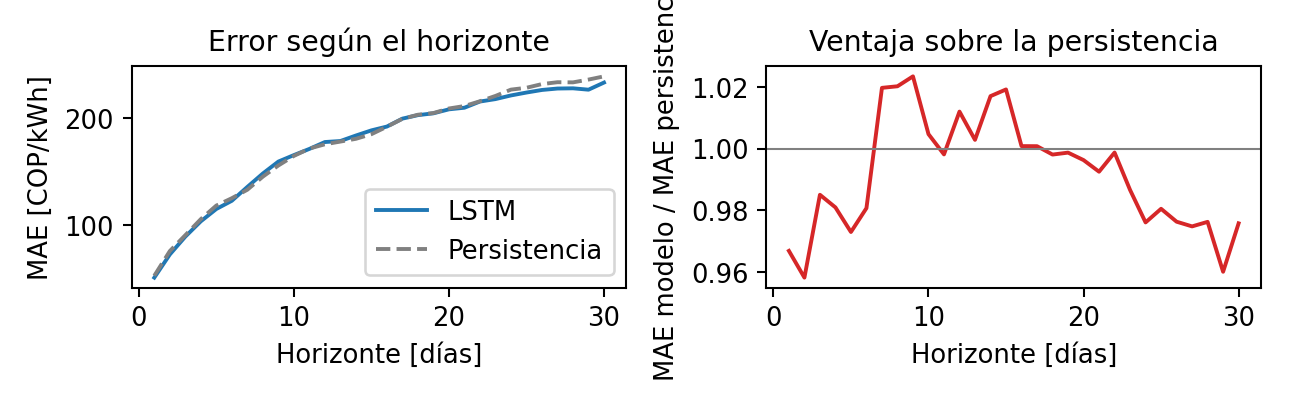


La razón va de 0.967 en h = 1 a 0.976 en h = 30.
Mejor en h = 2 (0.958); peor en h = 9 (1.023).
Horizontes en que no supera a la persistencia: 10 de 30.


In [11]:
# ============================================================
# 8.3 Cómo crece el error con el horizonte
# ============================================================
pers_test = s["precio_hoy"].values[I_PRUEBA]
filas_h = []
for k in range(HORIZONTE):
    real_h = REALES[I_PRUEBA][:, k]
    filas_h.append({"horizonte": k + 1,
                    "MAE_modelo": float(np.abs(real_h - TRAY[:, k]).mean()),
                    "MAE_persistencia": float(np.abs(real_h - pers_test).mean()),
                    "n": len(I_PRUEBA)})
por_horizonte = pd.DataFrame(filas_h)
por_horizonte["razon"] = por_horizonte["MAE_modelo"] / por_horizonte["MAE_persistencia"]
print(por_horizonte.loc[por_horizonte["horizonte"].isin([1, 2, 3, 7, 14, 21, 30])]
      .round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_modelo"], label="LSTM")
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_persistencia"], ls="--", color="grey",
             label="Persistencia")
axes[0].set_xlabel("Horizonte [días]"); axes[0].set_ylabel("MAE [COP/kWh]"); axes[0].legend()
axes[0].set_title("Error según el horizonte")
axes[1].plot(por_horizonte["horizonte"], por_horizonte["razon"], color="tab:red")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Horizonte [días]"); axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Ventaja sobre la persistencia")
a_escala(fig)
plt.tight_layout(); plt.show()

mejor_h = por_horizonte.loc[por_horizonte["razon"].idxmin()]
peor_h = por_horizonte.loc[por_horizonte["razon"].idxmax()]
print(f"\nLa razón va de {por_horizonte['razon'].iloc[0]:.3f} en h = 1 a "
      f"{por_horizonte['razon'].iloc[-1]:.3f} en h = 30.")
print(f"Mejor en h = {int(mejor_h['horizonte'])} ({mejor_h['razon']:.3f}); "
      f"peor en h = {int(peor_h['horizonte'])} ({peor_h['razon']:.3f}).")
print(f"Horizontes en que no supera a la persistencia: "
      f"{int((por_horizonte['razon'] >= 1).sum())} de {HORIZONTE}.")

In [12]:
# ============================================================
# 8.4 Desempeño por régimen ENSO y por año
# ============================================================
oni = s["indice_ONI_publicado"].values[I_PRUEBA]
fase = np.select([oni >= 0.5, oni <= -0.5], ["El Niño", "La Niña"], default="Neutral")
real_prom = REALES[I_PRUEBA].mean(axis=1)

# El año es el del DÍA PRONOSTICADO, no el del origen: es la misma agrupación de los notebooks 5 y
# 6 y la de la tabla del documento. Agrupar por el año del origen da otros recuentos —334 días en
# 2023 en vez de 304— y las cifras dejarían de ser comparables con las de las otras dos familias.
ANIO_OBJ = (origenes[I_PRUEBA] + pd.Timedelta(days=HORIZONTE)).year

cmp = pd.DataFrame({"fase": fase,
                    "anio": ANIO_OBJ,
                    "precio_medio": real_prom,
                    "e_pers": np.abs(real_prom - pers_test),
                    "e_lstm": np.abs(real_prom - TRAY.mean(axis=1))})
for clave, orden in (("fase", ["El Niño", "Neutral", "La Niña"]), ("anio", None)):
    g = cmp.groupby(clave).agg(n=("e_lstm", "size"), precio_medio=("precio_medio", "mean"),
                               Persistencia=("e_pers", "mean"), LSTM=("e_lstm", "mean"))
    if orden:
        g = g.loc[orden]
    g["ventaja_%"] = 100 * (1 - g["LSTM"] / g["Persistencia"])
    print(f"\nMAE sobre el promedio del mes, por {clave}:")
    print(g.round(1).to_string())


MAE sobre el promedio del mes, por fase:
           n  precio_medio  Persistencia   LSTM  ventaja_%
fase                                                      
El Niño  335         599.3         163.3  178.7       -9.4
Neutral  666         453.5         149.9  147.4        1.7
La Niña  154         234.9          88.8   60.2       32.2

MAE sobre el promedio del mes, por anio:
        n  precio_medio  Persistencia   LSTM  ventaja_%
anio                                                   
2023  304         576.0         163.5  180.4      -10.3
2024  366         670.9         213.6  208.6        2.3
2025  365         254.9          88.1   79.8        9.5
2026  120         210.4          68.3   58.2       14.9


In [13]:
# ============================================================
# 9. La comparación entre las tres familias
# ============================================================
p5 = pd.read_csv(os.path.join(PROC, "5_predicciones_sarimax.csv"), parse_dates=["fecha"])
p6 = pd.read_csv(os.path.join(PROC, "6_predicciones_xgboost.csv"), parse_dates=["fecha"])
BASE_SARIMAX = "SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema"
# EL XGBOOST DE LA COMPARACION ES EL DE LA TRAYECTORIA, el mismo que publica la tabla de
# errores. El archivo lleva tambien el estimador directo sobre el promedio, que da 143,10 en
# vez de 143,17; leerlo aqui hacia que esta tabla describiera otro modelo que el de la tabla
# de errores, y que las diferencias no cuadraran al restarlas. El guard de abajo lo verifica.
COL_XGB = next(c for c in p6.columns if "trayectoria" in c and "semilla_" not in c)

cmp3 = (pd.DataFrame({"fecha": origenes[I_PRUEBA], "real": real_prom,
                      "Persistencia": pers_test, "LSTM": TRAY.mean(axis=1)})
        .merge(p5[["fecha", BASE_SARIMAX]], on="fecha")
        .merge(p6[["fecha", COL_XGB]], on="fecha")
        .rename(columns={BASE_SARIMAX: "SARIMAX", COL_XGB: "XGBoost"}))
assert len(cmp3) == len(I_PRUEBA), f"la comparación perdió filas: {len(cmp3)} de {len(I_PRUEBA)}"

MODELOS_CMP = ["Persistencia", "SARIMAX", "XGBoost", "LSTM"]
res = pd.DataFrame([dict(modelo=m, **metricas(cmp3["real"], cmp3[m])) for m in MODELOS_CMP])
res["mejora_%"] = 100 * (1 - res["MAE"] / res.loc[0, "MAE"])

# Las dos familias anteriores tienen que reproducir sus cifras publicadas. Si no lo hacen, algo de
# este montaje no coincide con el de ellas y la comparación no significaría lo que dice significar.
# LAS CIFRAS PUBLICADAS NO SE COPIAN A MANO: se leen del consolidado, que es donde las dejó
# `registrar()`. Si un notebook anterior no se ha corrido, la búsqueda falla y lo dice.
# El consolidado guarda dos bloques por configuración —el entrenamiento, en muestra, y la
# prueba—, y esta comparación es sobre la PRUEBA: sin el filtro por bloque la misma clave
# devuelve dos filas y la búsqueda es ambigua.
CONS = pd.read_csv("resultados_modelos.csv")


def mae_publicado(notebook, modelo, trozo=""):
    f = CONS[(CONS["notebook"] == notebook) & (CONS["modelo"] == modelo)
             & (CONS["objetivo"] == "promedio_30d") & (CONS["bloque"] == "prueba")
             & CONS["configuracion"].str.contains(trozo, regex=False)]
    assert len(f) == 1, (f"{notebook} / {modelo} / «{trozo}» en la prueba: {len(f)} filas, "
                         f"se esperaba 1")
    return float(f["MAE"].iloc[0])


PUBLICADO = (
    ("Persistencia", mae_publicado("6_XGBoost_modelo_base",
                                   "Referencia: persistencia (P de hoy)")),
    ("SARIMAX", mae_publicado("5_SARIMAX_modelo_base", "SARIMAX", BASE_SARIMAX)),
    ("XGBoost", mae_publicado("6_XGBoost_modelo_base", "XGBoost", COL_XGB)),
)
for modelo, publicado in PUBLICADO:
    obtenido = float(res.loc[res["modelo"] == modelo, "MAE"].iloc[0])
    assert abs(obtenido - publicado) < 0.02, \
        f"{modelo} da {obtenido:.2f} aquí y {publicado} en su notebook: el montaje no coincide"

print("Las tres familias y la referencia, sobre el promedio del mes:")
print(res.round(2).to_string(index=False))
print("\nLas cifras de la persistencia, el SARIMAX y el XGBoost reproducen las de sus notebooks:")
print("  " + "  |  ".join(f"{v:.2f}".replace(".", ",") for _, v in PUBLICADO)
      + ". El montaje es el mismo.")

cmp3["fase"] = fase
cmp3["anio"] = ANIO_OBJ            # el año del día pronosticado, como en los notebooks 5 y 6
for clave, orden in (("fase", ["El Niño", "Neutral", "La Niña"]), ("anio", None)):
    g = pd.DataFrame({m: cmp3.groupby(clave).apply(
        lambda x, m=m: np.abs(x["real"] - x[m]).mean(), include_groups=False)
        for m in MODELOS_CMP})
    if orden:
        g = g.loc[orden]
    print(f"\nMAE por {clave}:")
    print(g.round(1).to_string())
    gana = int((g["LSTM"] < g[["SARIMAX", "XGBoost"]].min(axis=1)).sum())
    print(f"  {clave}s en que la LSTM supera a las dos familias anteriores: {gana} de {len(g)}")

Las tres familias y la referencia, sobre el promedio del mes:
      modelo    MAE   RMSE  SMAPE  mejora_%
Persistencia 145.66 232.21  30.54      0.00
     SARIMAX 136.70 206.31  28.66      6.15
     XGBoost 143.17 218.09  30.40      1.71
        LSTM 144.83 214.62  31.09      0.57

Las cifras de la persistencia, el SARIMAX y el XGBoost reproducen las de sus notebooks:
  145,66  |  136,70  |  143,17. El montaje es el mismo.

MAE por fase:
         Persistencia  SARIMAX  XGBoost   LSTM
fase                                          
El Niño         163.3    152.5    162.4  178.7
Neutral         149.9    144.5    149.5  147.4
La Niña          88.8     68.6     73.9   60.2
  fases en que la LSTM supera a las dos familias anteriores: 1 de 3

MAE por anio:
      Persistencia  SARIMAX  XGBoost   LSTM
anio                                       
2023         163.5    149.9    164.4  180.4
2024         213.6    205.5    210.7  208.6
2025          88.1     83.1     84.2   79.8
2026          68.3  

In [14]:
# ============================================================
# 9.1 Las métricas del entrenamiento, junto a las de la prueba
# ============================================================
# QUÉ FALTABA. Hasta aquí el notebook informa del error sobre la prueba y, en la rejilla, de la
# razón frente a la persistencia en los cinco pliegues de validación. Falta la otra mitad de la
# pregunta: cuánto acierta el modelo sobre los datos con los que se ajustó. Sin esa cifra el
# control del sobreajuste se puede argumentar —parar a tiempo— pero no medir.
#
# CÓMO SE MIDE, Y POR QUÉ ASÍ. Con el mismo rasero que la prueba: la configuración elegida se
# ajusta con el bloque de entrenamiento completo —el mismo ajuste que produce el primer
# pronóstico de la prueba— y se le piden las trayectorias de treinta días de ESOS MISMOS orígenes,
# los que el ajuste vio. NO se usa la pérdida de entrenamiento de Keras: mide el error del cambio
# logarítmico a la escala de la red, no el del precio a treinta días, y ponerla junto al MAE de la
# prueba diría que el modelo empeora un orden de magnitud al salir de la muestra cuando la mayor
# parte de esa diferencia sería solo el cambio de unidad.
from _entrenamiento import tabla_brecha, registrar_brecha, leer_brecha

I_ENTREN = indices_ajuste(ORIGENES_PRUEBA[0])
assert origenes[I_ENTREN].max() <= FIN_ENTRENAMIENTO, "el bloque en muestra entra en el embargo"

t0 = time.time()
TRAY_ENTREN = np.mean([ajustar_predecir(PARAMETROS, I_ENTREN, I_ENTREN, sm, EPOCAS)[0]
                       for sm in SEMILLAS], axis=0)
print(f"En muestra: {len(I_ENTREN)} origenes de {origenes[I_ENTREN].min().date()} a "
      f"{origenes[I_ENTREN].max().date()}, promediados sobre {len(SEMILLAS)} semillas "
      f"({time.time() - t0:.0f} s)")

PERS_ENTREN = np.repeat(s["precio_hoy"].values[I_ENTREN][:, None], HORIZONTE, axis=1)
BRECHA = tabla_brecha({"entrenamiento": (TRAY_ENTREN, REALES[I_ENTREN], PERS_ENTREN),
                       "prueba": (TRAY, REALES[I_PRUEBA], PERSIST)})
print()
print(BRECHA.round(3).to_string(index=False))
print()
print(leer_brecha(BRECHA))

registrar_brecha(BRECHA, notebook="7_LSTM_modelo_base", familia="Deep Learning", modelo="LSTM",
                 configuracion=f"{MEJOR} ({len(SEMILLAS)} semillas)",
                 particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                 reajuste_dias=None, verbose=True)

BRECHA.to_csv(os.path.join(PROC, "7_brecha_entrenamiento_prueba.csv"), index=False)
print(f"\n  [datasets/procesado] 7_brecha_entrenamiento_prueba.csv")

# ------------------------------------------------------------
# El error de CADA ventana de treinta días
# ------------------------------------------------------------
# La tabla de arriba resume cada bloque en una cifra, y una cifra no dice si el modelo acierta
# de forma pareja o alterna tramos buenos y malos. Se guarda el error de cada pronóstico por
# separado, con su persistencia, para poder ver cómo evoluciona a lo largo del periodo.
from _entrenamiento import error_por_origen

DETALLE = error_por_origen({"entrenamiento": (TRAY_ENTREN, REALES[I_ENTREN], PERS_ENTREN, origenes[I_ENTREN]),
                            "prueba": (TRAY, REALES[I_PRUEBA], PERSIST, origenes[I_PRUEBA])})
DETALLE.to_csv(os.path.join(PROC, "7_error_por_origen.csv"), index=False)
print(f"\n  [datasets/procesado] 7_error_por_origen.csv  "
      f"({len(DETALLE)} orígenes: "
      f"{(DETALLE['bloque'] == 'entrenamiento').sum()} en muestra y "
      f"{(DETALLE['bloque'] == 'prueba').sum()} de prueba)")
print(DETALLE.groupby("bloque")[["MAE", "MAE_persistencia", "razon"]].median().round(3)
      .to_string())

En muestra: 4568 origenes de 2010-06-30 a 2022-12-31, promediados sobre 5 semillas (36 s)

       bloque  n_origenes     objetivo     MAE    RMSE  SMAPE  MAE_persistencia  razon
entrenamiento        4568    pares_30d  48.427 100.332 23.074            52.768  0.918
       prueba        1155    pares_30d 176.935 276.195 37.763           178.369  0.992
entrenamiento        4568 promedio_30d  40.713  78.456 19.401            45.461  0.896
       prueba        1155 promedio_30d 144.835 214.621 31.088           145.662  0.994
entrenamiento        4568       dia_30  63.990 126.176 30.174            71.760  0.892
       prueba        1155       dia_30 233.476 339.407 50.134           239.273  0.976

El MAE pasa de 40.71 en el entrenamiento a 144.83 en la prueba, 3.56 veces mayor. La
persistencia pasa de 45.46 a 145.66 sobre los mismos orígenes, 3.20 veces, y la razón
frente a ella pasa de 0.896 a 0.994.
Descontado lo que sube la persistencia, queda un deterioro de 11 % en la razón:
hay brecha,


  [datasets/procesado] 7_error_por_origen.csv  (5723 orígenes: 4568 en muestra y 1155 de prueba)
                   MAE  MAE_persistencia  razon
bloque                                         
entrenamiento   29.078            30.763  0.962
prueba         123.778           118.754  0.991


Curva de aprendizaje de la configuracion elegida, promediada sobre los 5 pliegues (182 s):

 epocas  MAE_ajuste  MAE_validacion  razon_ajuste  razon_validacion
      3      34.321          49.535         0.923             0.955
      5      33.439          49.968         0.898             0.956
     10      29.639          52.238         0.791             0.993
     15      25.981          58.159         0.682             1.157
     30      18.659          70.295         0.486             1.389
     60      11.550          73.766         0.301             1.550

La razon frente a la persistencia es minima en el AJUSTE a las 60 epocas y en la VALIDACION a las 3.
  A partir de las 3 la red sigue mejorando sobre lo que ya vio y empeora sobre lo que no:
  eso es sobreajuste, y es lo que fija el numero de epocas en 3.


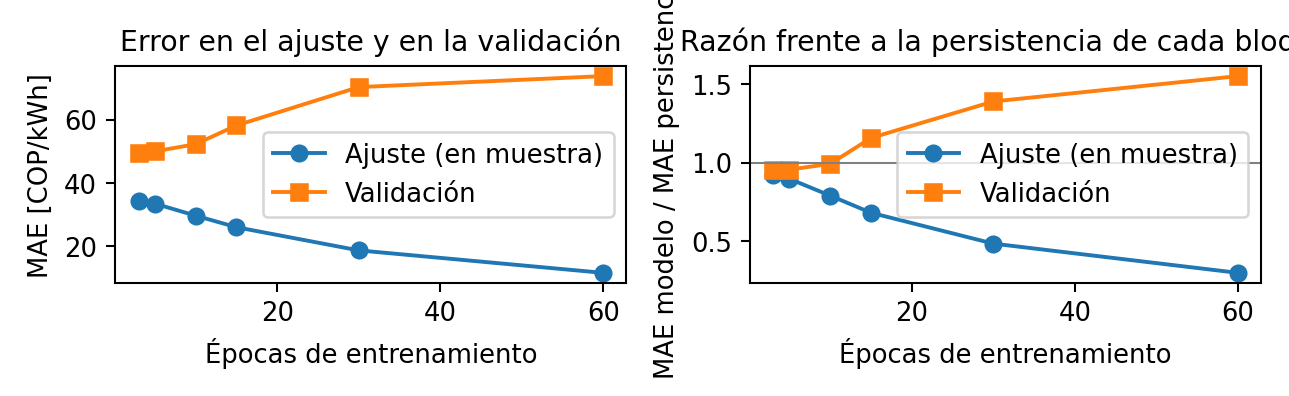


  [datasets/procesado] 7_curva_aprendizaje.csv


In [15]:
# ============================================================
# 9.2 La curva de aprendizaje: ajuste contra validación, época a época
# ============================================================
# Es la evidencia directa del sobreajuste de esta familia, y la que la rejilla solo podía
# insinuar. Allí se mide la razón de VALIDACIÓN en seis cortes de épocas; aquí se mide, en los
# mismos cortes y con la misma red, también el error sobre el conjunto de AJUSTE. Si la curva de
# ajuste baja mientras la de validación sube, lo que la red gana entrenando más es memoria.
#
# Se entrena UNA vez por pliegue hasta el último corte y se evalúa al pasar por cada uno: entrenar
# una red por corte repetiría el trabajo seis veces para obtener lo mismo.
def curva_ajuste_validacion(params, fin_ajuste, v_ini, v_fin, semilla=42):
    """MAE del promedio del mes sobre el ajuste y sobre la validación, en cada corte de épocas."""
    i_val = np.where((origenes >= pd.Timestamp(v_ini)) & (origenes <= pd.Timestamp(v_fin)))[0]
    i_aj = np.where((s["fecha_objetivo"] <= pd.Timestamp(fin_ajuste)).values & ~EN_EMBARGO)[0]
    assert origenes[i_aj].max() <= pd.Timestamp(fin_ajuste), "la purga no cierra antes del pliegue"
    X_aj, X_ev = escalar(i_aj, i_val)
    modelo = construir_modelo(semilla=semilla, **params)

    def mae(i, X):
        z = modelo.predict([X, ESTATICAS[i].astype("float32")], verbose=0)
        pred = s["precio_hoy"].values[i][:, None] * np.exp(z)
        return float(np.abs(REALES[i].mean(axis=1) - pred.mean(axis=1)).mean())

    per = {"ajuste": float(np.abs(REALES[i_aj].mean(axis=1)
                                  - s["precio_hoy"].values[i_aj]).mean()),
           "validacion": float(np.abs(REALES[i_val].mean(axis=1)
                                      - s["precio_hoy"].values[i_val]).mean())}
    filas, hechas = [], 0
    for corte in CORTES:
        modelo.fit([X_aj, ESTATICAS[i_aj].astype("float32")], Z[i_aj].astype("float32"),
                   epochs=corte - hechas, batch_size=64, verbose=0, shuffle=True)
        hechas = corte
        m_aj, m_val = mae(i_aj, X_aj), mae(i_val, X_ev)
        filas.append({"epocas": corte, "MAE_ajuste": m_aj, "MAE_validacion": m_val,
                      "razon_ajuste": m_aj / per["ajuste"],
                      "razon_validacion": m_val / per["validacion"]})
    return pd.DataFrame(filas)


t0 = time.time()
curvas_ap = [curva_ajuste_validacion(PARAMETROS, *pl) for pl in PLIEGUES]
CURVA = (pd.concat(curvas_ap).groupby("epocas").mean().reset_index())
print(f"Curva de aprendizaje de la configuracion elegida, promediada sobre los "
      f"{len(PLIEGUES)} pliegues ({time.time() - t0:.0f} s):\n")
print(CURVA.round(3).to_string(index=False))

# SE LEE LA RAZÓN, NO EL MAE CRUDO. Los cinco pliegues caen en tramos de distinto nivel de precio
# y promediar sus MAE pondera los caros; la razón frente a la persistencia de cada pliegue es la
# cantidad con la que se eligió la configuración. Si las dos no apuntan al mismo corte, se dice.
_c = CURVA.set_index("epocas")
_opt_aj = int(_c["razon_ajuste"].idxmin())
_opt_val = int(_c["razon_validacion"].idxmin())
_opt_mae = int(_c["MAE_validacion"].idxmin())
print(f"\nLa razon frente a la persistencia es minima en el AJUSTE a las {_opt_aj} epocas "
      f"y en la VALIDACION a las {_opt_val}.")
if _opt_mae != _opt_val:
    print(f"  El MAE crudo de validacion, en cambio, es minimo a las {_opt_mae}: entre los dos "
          f"cortes hay\n  "
          f"{abs(_c.loc[_opt_mae, 'MAE_validacion'] - _c.loc[_opt_val, 'MAE_validacion']):.2f}"
          f" COP/kWh de diferencia, y no coinciden porque cada pliegue\n  tiene su propio nivel "
          f"de persistencia.")
if _opt_aj > _opt_val:
    print(f"  A partir de las {_opt_val} la red sigue mejorando sobre lo que ya vio y empeora "
          f"sobre lo que no:\n  eso es sobreajuste, y es lo que fija el numero de epocas en "
          f"{EPOCAS}.")
else:
    print("  Las dos curvas tienen su mínimo en el mismo corte: la rejilla no separa aquí el "
          "ajuste\n  de la generalización, y el número de épocas no se puede justificar por esta "
          "via.")

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(CURVA["epocas"], CURVA["MAE_ajuste"], marker="o", label="Ajuste (en muestra)")
axes[0].plot(CURVA["epocas"], CURVA["MAE_validacion"], marker="s", label="Validación")
axes[0].set_xlabel("Épocas de entrenamiento"); axes[0].set_ylabel("MAE [COP/kWh]")
axes[0].set_title("Error en el ajuste y en la validación"); axes[0].legend()
axes[1].plot(CURVA["epocas"], CURVA["razon_ajuste"], marker="o", label="Ajuste (en muestra)")
axes[1].plot(CURVA["epocas"], CURVA["razon_validacion"], marker="s", label="Validación")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Épocas de entrenamiento")
axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Razón frente a la persistencia de cada bloque"); axes[1].legend()
a_escala(fig)
plt.tight_layout()
plt.show()

CURVA.to_csv(os.path.join(PROC, "7_curva_aprendizaje.csv"), index=False)
print(f"\n  [datasets/procesado] 7_curva_aprendizaje.csv")


In [16]:
# ============================================================
# 10. Archivos de salida
# ============================================================
pred_guardar = pd.DataFrame({"fecha": origenes[I_PRUEBA],
                             "fecha_objetivo": origenes[I_PRUEBA] + pd.Timedelta(days=HORIZONTE),
                             "real": real_prom, "persistencia": pers_test,
                             MEJOR: TRAY.mean(axis=1)})
# `MEJOR` ya empieza por «LSTM», de modo que anteponerle la familia da «LSTM LSTM 32, 3 épocas».
assert not any(c.startswith("LSTM LSTM") for c in pred_guardar.columns), "etiqueta duplicada"
for k, (semilla, p) in enumerate(por_semilla.items()):
    pred_guardar[f"LSTM semilla {semilla}"] = p.mean(axis=1)
pred_guardar.to_csv(os.path.join(PROC, "7_predicciones_lstm.csv"), index=False)

res.to_csv(os.path.join(PROC, "7_metricas_lstm.csv"), index=False)
por_horizonte.to_csv(os.path.join(PROC, "7_error_por_horizonte_lstm.csv"), index=False)
np.save(os.path.join(PROC, "7_trayectoria_lstm.npy"), TRAY)

_, _, modelo_final = walk_forward(PARAMETROS, SEMILLAS[0], EPOCAS,
                                  i_objetivo=I_PRUEBA[-PASO_WFV:], traza=True)
modelo_final.save(os.path.join(MODELOS, "lstm_base.keras"))

print("Guardado en datasets/procesado:")
print("  7_predicciones_lstm.csv, 7_metricas_lstm.csv, 7_error_por_horizonte_lstm.csv,")
print("  7_trayectoria_lstm.npy (la matriz 1.155 x 30, para no reentrenar al analizarla)")
print("Guardado en models/baseline/LSTM:  lstm_base.keras (el último reajuste)")
print("Filas en resultados_modelos.csv: las tres lecturas de la LSTM y de las dos referencias.")

Guardado en datasets/procesado:
  7_predicciones_lstm.csv, 7_metricas_lstm.csv, 7_error_por_horizonte_lstm.csv,
  7_trayectoria_lstm.npy (la matriz 1.155 x 30, para no reentrenar al analizarla)
Guardado en models/baseline/LSTM:  lstm_base.keras (el último reajuste)
Filas en resultados_modelos.csv: las tres lecturas de la LSTM y de las dos referencias.


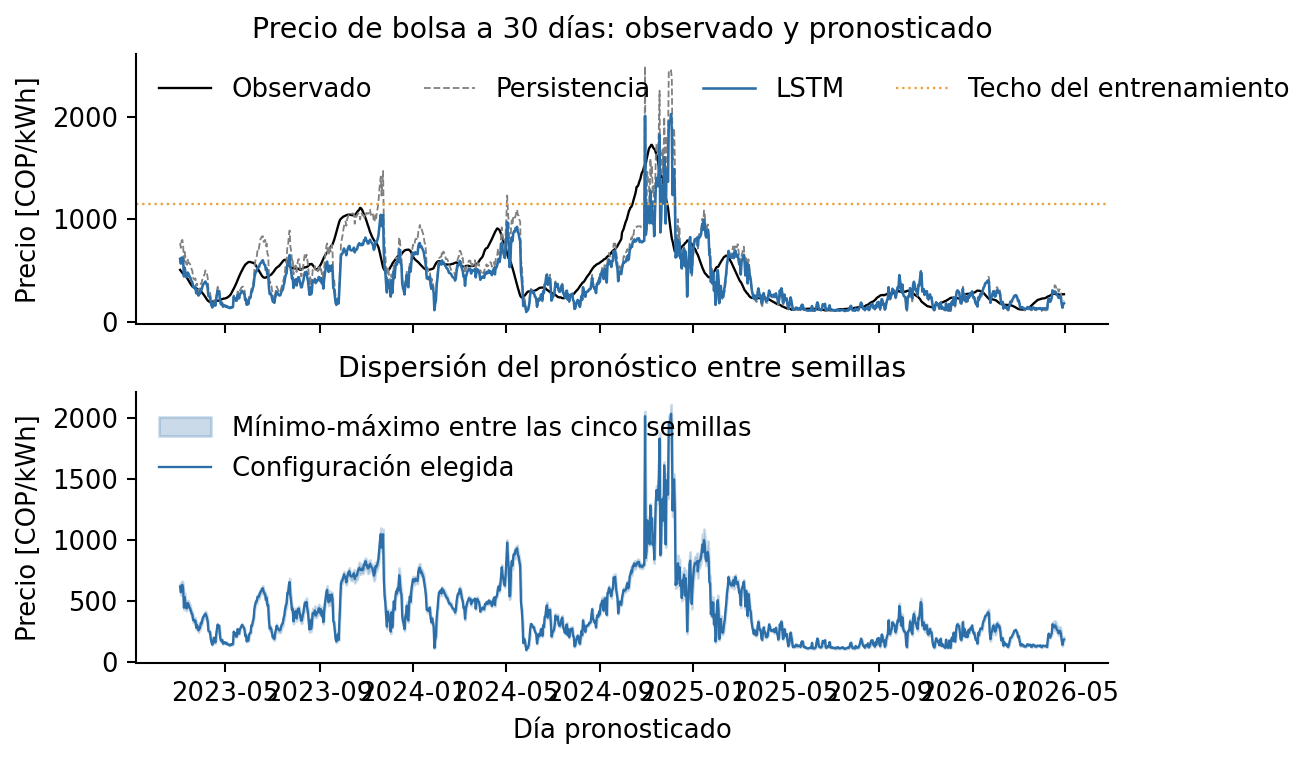

Techo del entrenamiento: 1147.9 COP/kWh
El pronóstico llega a 2032 COP/kWh y supera ese techo en 27 de los 1155 días pronosticados.
Amplitud media de la banda entre las cinco semillas: 32.2 COP/kWh


In [17]:
# ============================================================
# 11. El pronóstico sobre el periodo de prueba
# ============================================================
# ESTA ES LA FIGURA QUE VA AL DOCUMENTO, y la dibuja `_figuras.pronostico`, que es el mismo código
# para las cinco familias. Si cada cuaderno la dibujara por su cuenta, a la primera corrección en
# uno solo de ellos las figuras dejarían de ser comparables sin que nada avisara, y comparar
# familias es justamente lo que el trabajo hace.
#
# NO SE REENTRENA NI SE LEE NADA: se dibuja `pred_guardar`, que es lo que la celda anterior acaba
# de guardar como el archivo de predicciones. El techo del entrenamiento sí se lee del dataset de
# selección, para que las cinco familias marquen exactamente la misma línea.
from _figuras import pronostico, techo_entrenamiento, PROPORCION_PRONOSTICO

TECHO = techo_entrenamiento(PROC, FIN_ENTRENAMIENTO)
fig, datos = pronostico(pred_guardar, MEJOR, "LSTM semilla ", "LSTM", TECHO,
                        a_escala, ANCHO_PAGINA, alto_pagina(*PROPORCION_PRONOSTICO))
plt.show();

print(f"Techo del entrenamiento: {datos['techo']:.1f} COP/kWh")
print(f"El pronóstico llega a {datos['maximo_pronosticado']:.0f} COP/kWh y supera ese techo en "
      f"{datos['dias_sobre_techo']} de los {len(pred_guardar)} días pronosticados.")
print(f"Amplitud media de la banda entre las cinco semillas: {datos['amplitud_banda']:.1f} COP/kWh")

## 12. Conclusiones y limitaciones

*Las cifras de esta sección se leen de las salidas de arriba.

### Limitaciones que conviene declarar

- **El grano de la entrada no es el mismo que el de las otras dos familias.** La ventana da a la red los treinta valores diarios individuales; los árboles los vieron agregados en medias y rezagos.
- **El escalador se reajusta por bloque, y el nivel del precio se multiplica por 2,43 entre entrenamiento y prueba.** La escala logarítmica comprime ese salto, pero no lo elimina: en los bloques iniciales de la prueba la red recibe entradas desplazadas respecto….
- **El número de épocas se elige sobre pliegues más pequeños que los bloques de la corrida final.** Los conjuntos de ajuste de los cinco pliegues van de 886 a 3.808 orígenes, y los de la validación progresiva empiezan en 4.568.
- **La rejilla recorre tres arquitecturas y seis valores de épocas**, elegidos por criterio y no por barrido.
- **No se produce pronóstico probabilístico.**
- **Una sola arquitectura recurrente.**

### Siguiente paso

El GRU sobre el mismo montaje: misma ventana, mismas estáticas, mismo objetivo relativo, misma rejilla y mismas semillas.